# Urban Sound Intelligence — CDS701 全流程 Notebook

本 Notebook 严格按 UrbanSound8K **官方 Fold**（Fold 1-8 训练 / Fold 9 验证 / Fold 10 测试）跑通完整实验：

MFCC 特征 → SVM / Random Forest / MLP → PCA 降维 → 白噪声鲁棒性 → 打包模型与结果。

**使用方式（二选一）**
1. 在下面的单元格填写 `REPO_URL`，运行时自动 `git clone`；
2. 或者把 `Urban-Sound-Intelligence` 文件夹整体上传到 `/content` 后再运行。

**运行环境**：CPU 即可，无需 GPU。完整流程约 1.5–2.5 小时（含约 6 GB 数据下载与两轮 MFCC 提取）。

> 所有指标都由本 Notebook 实际计算产生，仓库中不预置任何结果数值。


In [1]:
#@title 1. 准备项目目录 { display-mode: "form" }
import os
import pathlib
import subprocess
import sys

REPO_URL = "https://github.com/hanjinyi2003-create/Urban-Sound-Intelligence.git"
PROJECT_DIR = pathlib.Path("/content/Urban-Sound-Intelligence")

if not PROJECT_DIR.exists():
    if REPO_URL.strip():
        subprocess.run(["git", "clone", REPO_URL, str(PROJECT_DIR)], check=True)
    else:
        raise SystemExit(
            "未找到项目代码：请把 Urban-Sound-Intelligence 文件夹上传到 /content，"
            "或在 REPO_URL 中填写仓库地址。"
        )

os.chdir(PROJECT_DIR)
print("工作目录：", pathlib.Path.cwd())


def run(module, *args):
    """用当前解释器执行项目模块，保证与 Notebook 环境一致。"""
    printable = " ".join(str(a) for a in args)
    print(f"\n>>> python -m {module} {printable}")
    subprocess.run(
        [sys.executable, "-m", module, *[str(a) for a in args]],
        check=True,
        cwd=str(PROJECT_DIR),
    )


工作目录： /content/Urban-Sound-Intelligence


In [2]:
#@title 2. 安装依赖（约 2-3 分钟）
!pip install -q -r requirements.txt
import librosa, sklearn
print("librosa", librosa.__version__, "| scikit-learn", sklearn.__version__)


librosa 0.11.0 | scikit-learn 1.6.1


In [3]:
#@title 3. 下载并解压 UrbanSound8K（约 6 GB）
import pathlib
import subprocess

ARCHIVE = pathlib.Path("/content/UrbanSound8K.tar.gz")
URL = "https://zenodo.org/records/1203745/files/UrbanSound8K.tar.gz?download=1"
METADATA = pathlib.Path("data/UrbanSound8K/metadata/UrbanSound8K.csv")

if not METADATA.exists():
    if not ARCHIVE.exists():
        subprocess.run(
            ["wget", "-q", "--show-progress", "-O", str(ARCHIVE), URL], check=True
        )
    pathlib.Path("data").mkdir(exist_ok=True)
    subprocess.run(["tar", "-xzf", str(ARCHIVE), "-C", "data"], check=True)
    print("解压完成")

audio_files = list(pathlib.Path("data/UrbanSound8K/audio").rglob("*.wav"))
print("音频文件数：", len(audio_files), "（官方应为 8732）")
assert len(audio_files) == 8732, "音频数量不符，请检查解压是否完整"


解压完成
音频文件数： 8732 （官方应为 8732）



>>> python -m preprocessing.dataset_analysis 


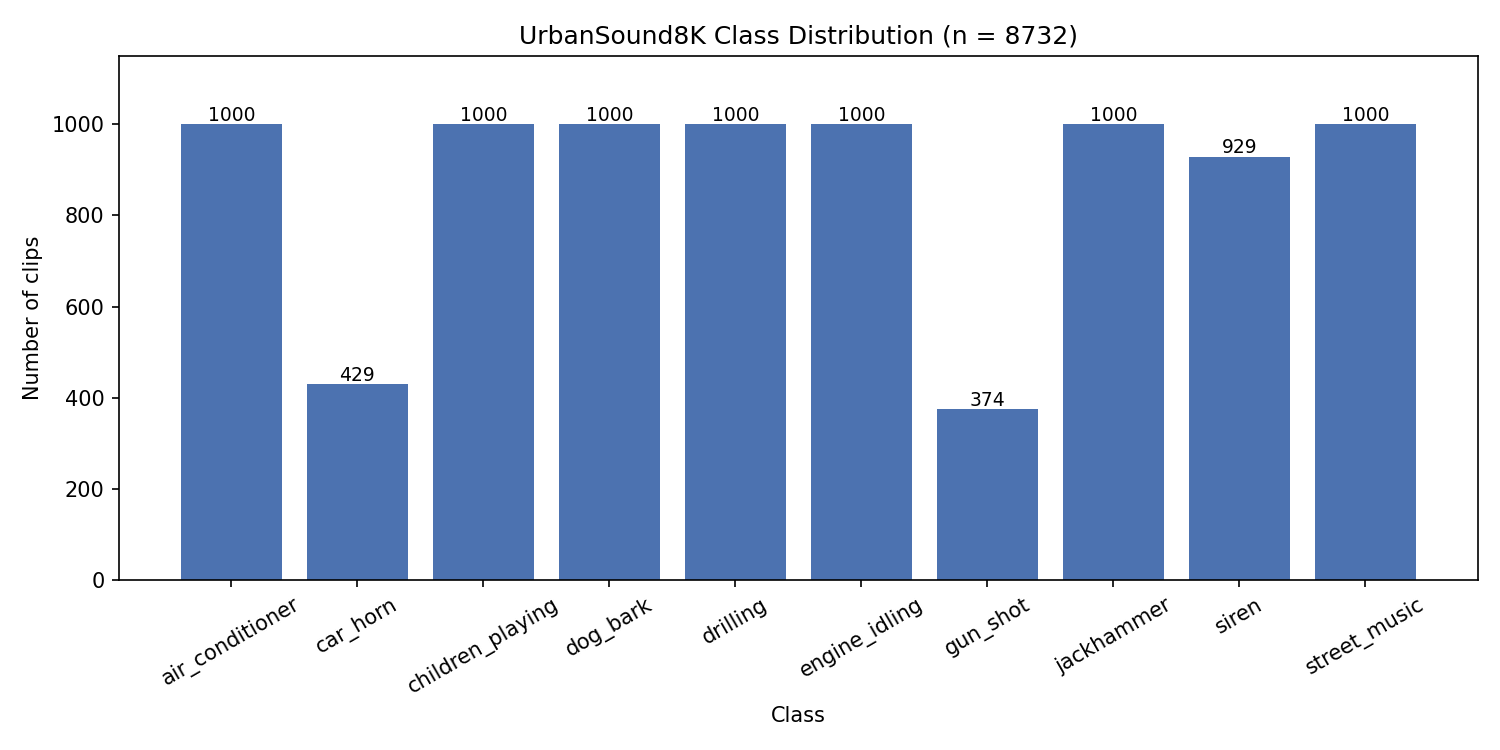

In [4]:
#@title 4. 数据集检查与类别分布（Member 1）
run("preprocessing.dataset_analysis")

from IPython.display import Image, display
display(Image(filename="results/figures/class_distribution.png"))


In [13]:
#@title 5. MFCC 特征提取 + 官方 Fold 划分（Member 1，约 30-50 分钟）
run("preprocessing.feature_extraction")
run("preprocessing.data_split")

import json, pathlib
info = json.loads(pathlib.Path("data/processed/split_info.json").read_text(encoding="utf-8"))
print(json.dumps(info, ensure_ascii=False, indent=2))



>>> python -m preprocessing.feature_extraction 

>>> python -m preprocessing.data_split 
{
  "split_policy": "UrbanSound8K official folds (no random shuffling)",
  "train_folds": [
    1,
    2,
    3,
    4,
    5,
    6,
    7,
    8
  ],
  "val_fold": 9,
  "test_fold": 10,
  "n_train": 7079,
  "n_val": 816,
  "n_test": 837,
  "n_features": 40,
  "class_names": [
    "air_conditioner",
    "car_horn",
    "children_playing",
    "dog_bark",
    "drilling",
    "engine_idling",
    "gun_shot",
    "jackhammer",
    "siren",
    "street_music"
  ],
  "leakage_check": "passed (train/val/test share no audio file)"
}


In [14]:
#@title 6a. SVM 调参与训练（Member 2）
run("models.svm_training")



>>> python -m models.svm_training 



>>> python -m models.rf_training 

>>> python -m models.feature_importance 


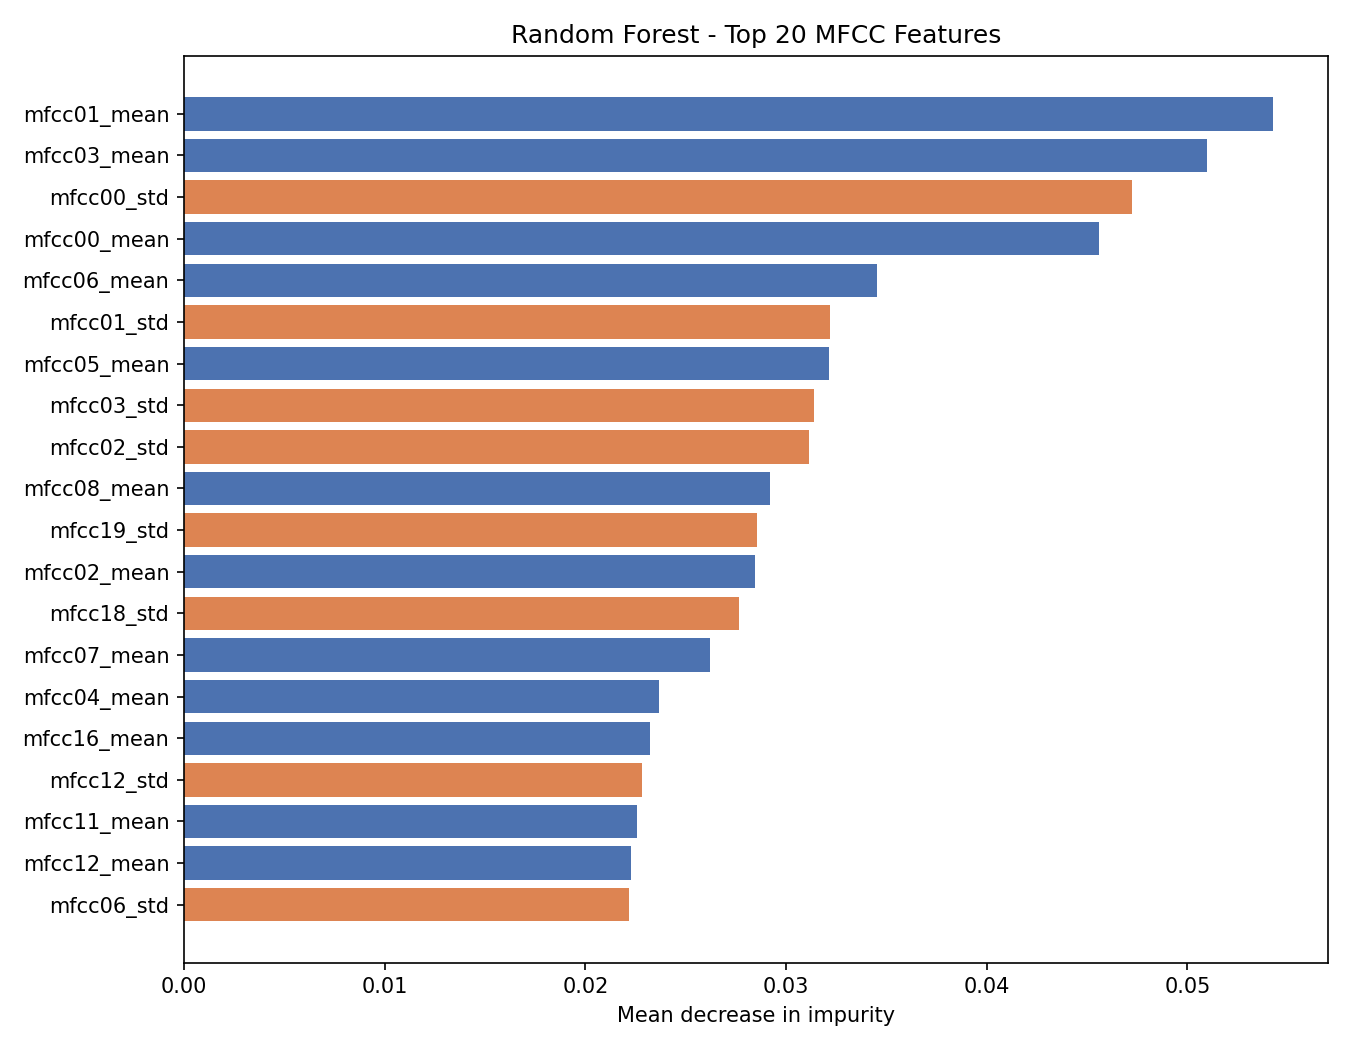

In [7]:
#@title 6b. Random Forest 训练与特征重要性（Member 3）
run("models.rf_training")
run("models.feature_importance")

from IPython.display import Image, display
display(Image(filename="results/figures/rf_feature_importance.png"))


In [8]:
#@title 6c. MLP 训练（Member 4）
run("models.mlp_training")



>>> python -m models.mlp_training 



>>> python -m experiments.evaluation 


,model,accuracy,macro_precision,macro_recall,macro_f1,train_seconds
0,SVM (RBF),0.7085,0.7373,0.7028,0.7134,8.24
1,Random Forest,0.7013,0.7401,0.6856,0.7036,17.16
2,MLP,0.6667,0.7096,0.6656,0.6786,20.43


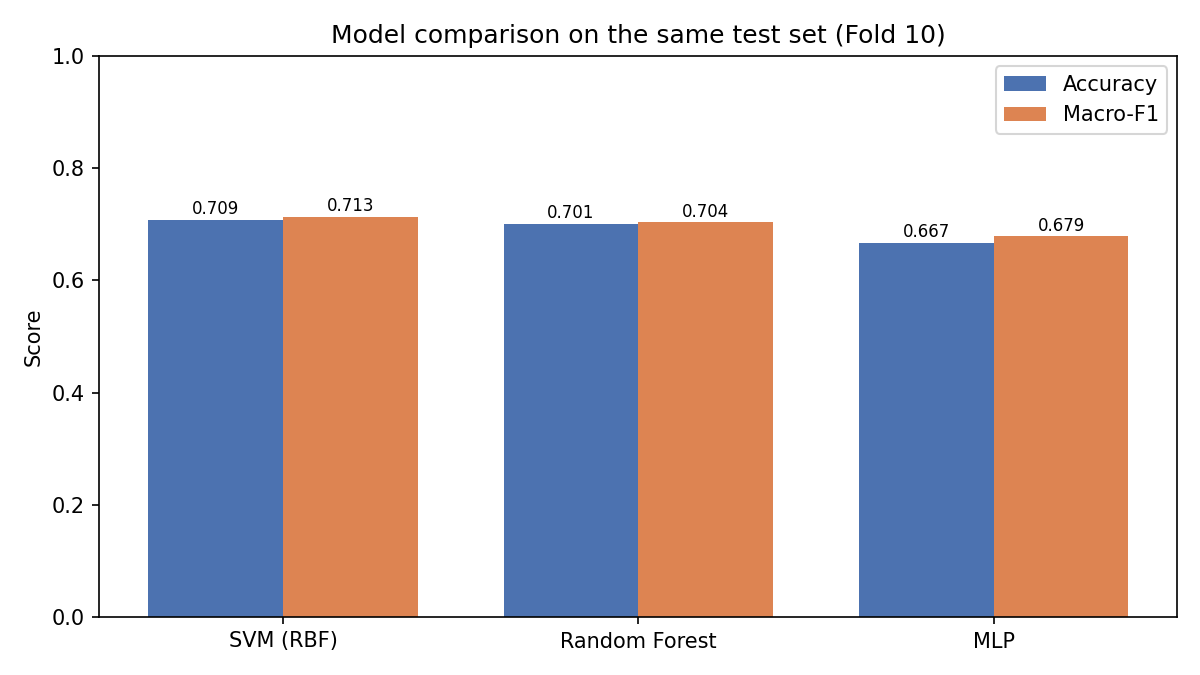

In [9]:
#@title 7. 三模型统一测试集对比
run("experiments.evaluation")

import pandas as pd
from IPython.display import Image, display

display(pd.read_csv("results/tables/model_comparison.csv"))
display(Image(filename="results/figures/model_comparison.png"))



>>> python -m experiments.pca_experiment 


,variant,n_components,explained_variance,accuracy,macro_precision,macro_recall,macro_f1,train_seconds,predict_seconds,predict_ms_per_sample
0,Raw 40-dim,40,1.0000,0.7085,0.7373,0.7028,0.7134,1.35,0.335,0.400
1,PCA 20 components,20,0.9004,0.6703,0.6927,0.6708,0.6732,1.20,0.310,0.371
2,PCA 95% variance,27,0.9553,0.7121,0.7306,0.7033,0.7113,1.99,0.525,0.627


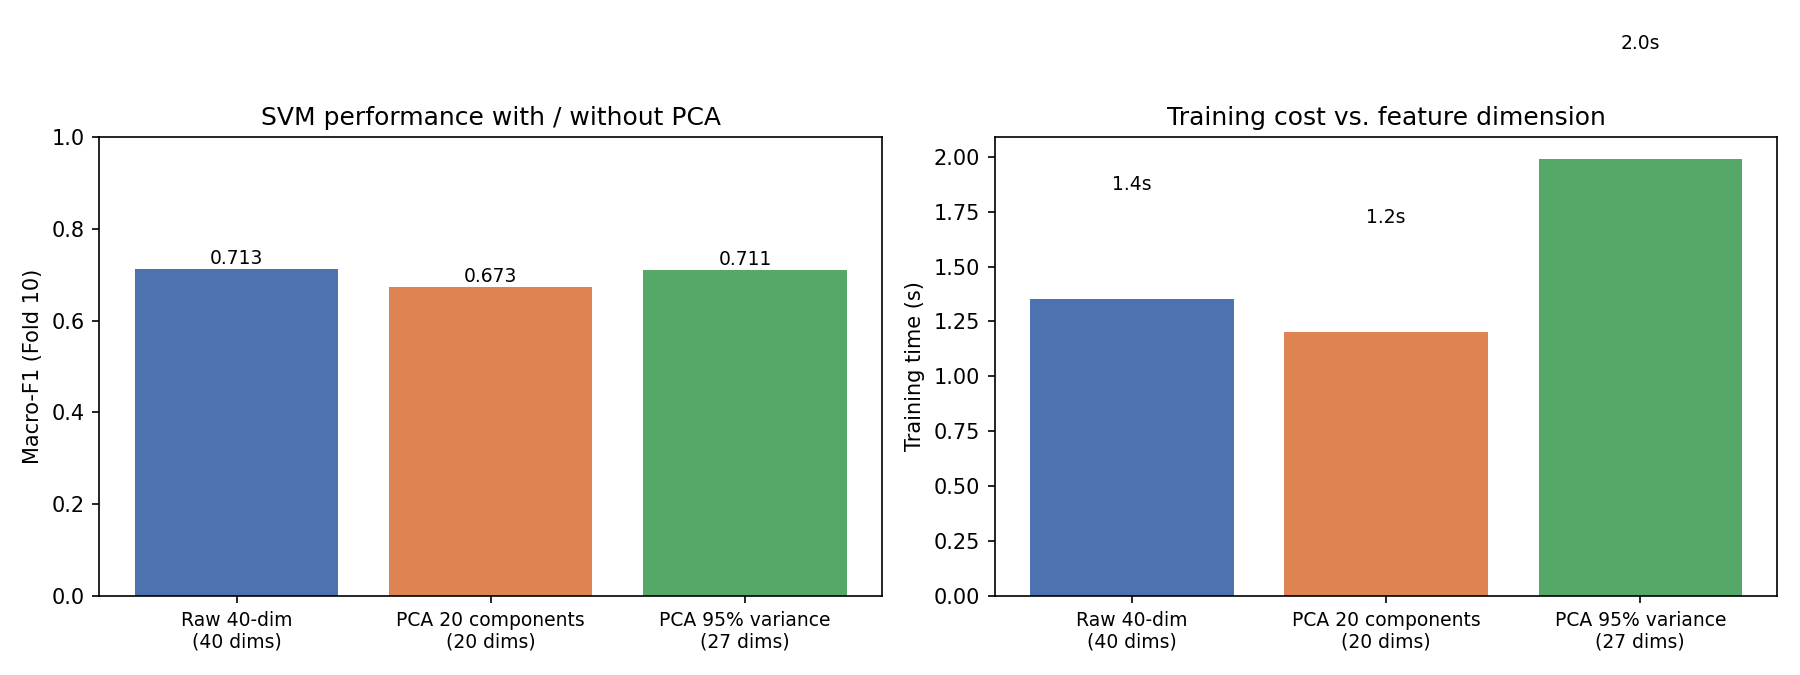

In [10]:
#@title 8. PCA 降维实验（Member 2）
run("experiments.pca_experiment")

import pandas as pd
from IPython.display import Image, display

display(pd.read_csv("results/tables/pca_results.csv"))
display(Image(filename="results/figures/pca_comparison.png"))



>>> python -m experiments.noise_generator --snr 20 10

>>> python -m experiments.robustness_test 


,model,condition,snr_db,accuracy,macro_precision,macro_recall,macro_f1,n_samples
0,SVM (RBF),Clean,NaN,0.7085,0.7373,0.7028,0.7134,837
1,SVM (RBF),20 dB,20.0,0.6440,0.7001,0.6187,0.6358,837
2,SVM (RBF),10 dB,10.0,0.4158,0.5545,0.3756,0.3742,837
3,Random Forest,Clean,NaN,0.7013,0.7401,0.6856,0.7036,837
4,Random Forest,20 dB,20.0,0.6404,0.7146,0.5809,0.5955,837
5,Random Forest,10 dB,10.0,0.4182,0.4753,0.3594,0.3669,837
6,MLP,Clean,NaN,0.6667,0.7096,0.6656,0.6786,837
7,MLP,20 dB,20.0,0.5878,0.6373,0.5829,0.5942,837
8,MLP,10 dB,10.0,0.4050,0.5289,0.3799,0.3858,837


,condition,target_snr_db,measured_snr_db,n_samples,n_features
0,20 dB,20.0,20.0,837,40
1,10 dB,10.0,10.0,837,40


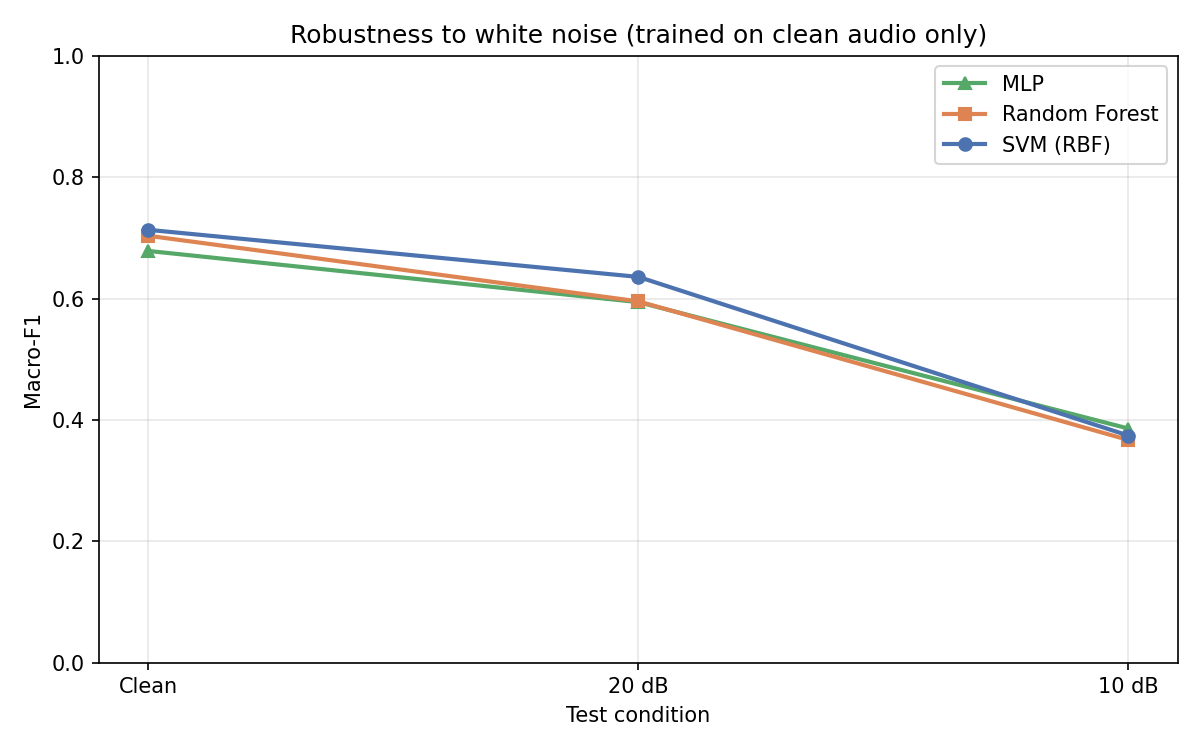

In [11]:
#@title 9. 白噪声鲁棒性实验（Member 4，约 20-30 分钟）
run("experiments.noise_generator", "--snr", 20, 10)
run("experiments.robustness_test")

import pandas as pd
from IPython.display import Image, display

display(pd.read_csv("results/tables/robustness_results.csv"))
display(pd.read_csv("results/tables/noise_conditions.csv"))
display(Image(filename="results/figures/robustness_macro_f1.png"))


In [15]:
#@title 10. 打包模型、指标与图表并下载
import pathlib
import zipfile

from google.colab import files

ARCHIVE = pathlib.Path("/content/urban_sound_artifacts.zip")
KEEP_SUFFIXES = {".joblib", ".json", ".csv", ".png", ".py", ".md", ".txt"}
ITEMS = [
    "saved_models",
    "results",
    "preprocessing",
    "models",
    "experiments",
    "demo",
    "config.py",
    "requirements.txt",
    "README.md",
    "data/processed/split_info.json",
    "data/processed/test_files.csv",
    "data/processed/feature_config.json",
]

with zipfile.ZipFile(ARCHIVE, "w", zipfile.ZIP_DEFLATED) as archive:
    for item in ITEMS:
        path = pathlib.Path(item)
        if path.is_dir():
            for file in path.rglob("*"):
                if file.is_file() and file.suffix in KEEP_SUFFIXES:
                    archive.write(file, file.as_posix())
        elif path.exists():
            archive.write(path, path.as_posix())

print(f"已打包 {ARCHIVE}（{ARCHIVE.stat().st_size / 1e6:.1f} MB）")
files.download(str(ARCHIVE))


已打包 /content/urban_sound_artifacts.zip（19.0 MB）


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 完成情况自查

| 文档要求 | 本 Notebook 对应位置 |
|---|---|
| UrbanSound8K 数据处理、MFCC | 单元格 3–5 |
| SVM / RF / MLP 训练 | 单元格 6a / 6b / 6c |
| Accuracy、Macro-F1、Confusion Matrix | 各模型训练输出 + `results/figures/*_confusion_matrix.png` |
| 白噪声鲁棒性（Clean / 20 dB / 10 dB） | 单元格 9 |
| PCA 降维对比 | 单元格 8 |
| Streamlit Demo | 下载压缩包后在本地执行 `streamlit run demo/app.py` |

**重要**：官方 Fold 划分不可替换为随机切分，否则同一原始录音会同时出现在训练集与测试集。
若需要更稳健的结论，可在此之上补充 10 折轮流验证（每折整折留出），但仍禁止跨折随机抽样。

在 Colab 中预览 Demo（可选，需额外安装）：

```python
!npm install -g localtunnel -s
get_ipython().system_raw('streamlit run demo/app.py --server.port 8501 &')
print(get_ipython().system('curl -s https://loca.lt/mytunnelpassword'))
print(get_ipython().system('npx localtunnel --port 8501'))
```
